In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define dataset path

DATA_DIR = Path("../data/raw")

# Load datasets

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
test_label_df = pd.read_csv(DATA_DIR / "test_label.csv")

print("Datasets loaded successfully!")

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)
print("Test Labels Shape:", test_label_df.shape)

Datasets loaded successfully!
Training Shape: (132481, 26)
Testing Shape: (87841, 26)
Test Labels Shape: (87841, 2)


In [3]:
# Identify feature columns

timestamp_col = "timestamp_(min)"

feature_cols = [
    col for col in train_df.columns
    if col != timestamp_col
]

# Calculate missing values

missing_summary = pd.DataFrame({
    "Missing Count": train_df[feature_cols].isnull().sum(),
    "Missing Percentage": (
        train_df[feature_cols].isnull().mean() * 100
    )
})

missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_summary.round(4))

,Missing Count,Missing Percentage
feature_21,2136,1.6123
feature_6,563,0.4250
feature_5,249,0.1880
feature_13,249,0.1880
feature_22,204,0.1540
feature_14,202,0.1525
feature_4,202,0.1525
feature_18,202,0.1525
feature_8,47,0.0355
feature_7,47,0.0355


In [4]:
# Analyze consecutive missing value intervals

missing_intervals = []

for col in feature_cols:

    missing_positions = np.flatnonzero(
        train_df[col].isna().to_numpy()
    )

    if len(missing_positions) == 0:
        continue

    # Split missing positions into consecutive groups

    groups = np.split(
        missing_positions,
        np.where(np.diff(missing_positions) > 1)[0] + 1
    )

    for group in groups:

        start_row = int(group[0])
        end_row = int(group[-1])

        missing_intervals.append({

            "Feature": col,

            "Start Row": start_row,

            "End Row": end_row,

            "Start Timestamp": train_df[
                timestamp_col
            ].iloc[start_row],

            "End Timestamp": train_df[
                timestamp_col
            ].iloc[end_row],

            "Missing Count": len(group)
        })

# Create DataFrame

interval_df = pd.DataFrame(missing_intervals)

interval_df = interval_df.sort_values(
    by=["Feature", "Start Row"]
).reset_index(drop=True)

print("TOTAL CONSECUTIVE MISSING INTERVALS:",
      len(interval_df))

display(interval_df)

TOTAL CONSECUTIVE MISSING INTERVALS: 17


,Feature,Start Row,End Row,Start Timestamp,End Timestamp,Missing Count
0,feature_10,21038,21084,21038.0,21084.0,47
1,feature_13,21038,21084,21038.0,21084.0,47
2,feature_13,85625,85826,85625.0,85826.0,202
3,feature_14,85625,85826,85625.0,85826.0,202
4,feature_18,85625,85826,85625.0,85826.0,202
5,feature_21,3961,4319,3961.0,4319.0,359
6,feature_21,18001,19573,18001.0,19573.0,1573
7,feature_21,20881,21084,20881.0,21084.0,204
8,feature_22,20881,21084,20881.0,21084.0,204
9,feature_24,21038,21084,21038.0,21084.0,47


In [5]:
# Summarize missing intervals by feature

gap_summary = (
    interval_df.groupby("Feature")
    .agg(
        Number_of_Gaps=("Missing Count", "count"),
        Total_Missing=("Missing Count", "sum"),
        Longest_Gap=("Missing Count", "max")
    )
    .sort_values(
        by="Longest_Gap",
        ascending=False
    )
)

display(gap_summary)

,Number_of_Gaps,Total_Missing,Longest_Gap
Feature,,,
feature_21,3,2136,1573
feature_6,2,563,359
feature_22,1,204,204
feature_13,2,249,202
feature_5,2,249,202
feature_18,1,202,202
feature_14,1,202,202
feature_4,1,202,202
feature_10,1,47,47


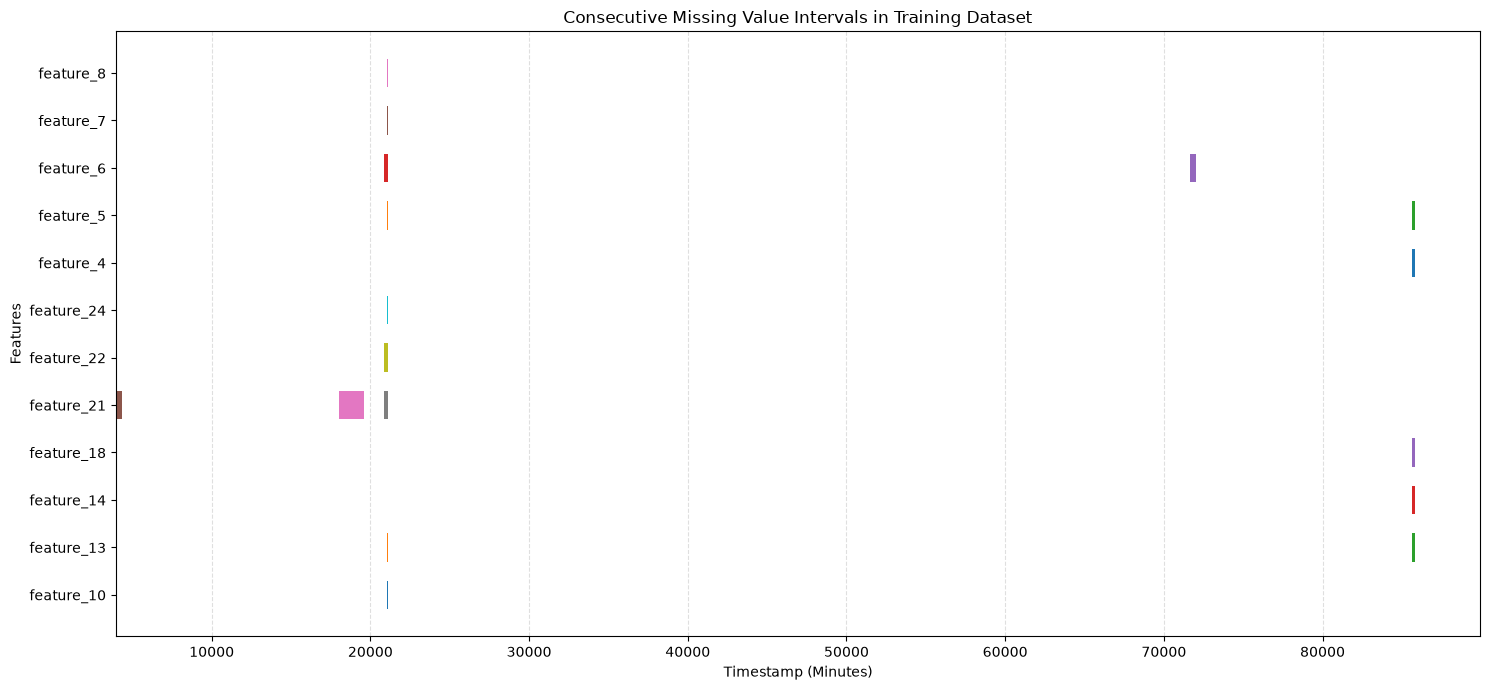

In [6]:

# Visualize consecutive missing intervals

plt.figure(figsize=(15, 7))

for _, row in interval_df.iterrows():

    start = row["Start Timestamp"]
    end = row["End Timestamp"]

    plt.barh(
        row["Feature"],
        end - start + 1,
        left=start,
        height=0.6
    )

plt.xlabel("Timestamp (Minutes)")
plt.ylabel("Features")

plt.title(
    "Consecutive Missing Value Intervals "
    "in Training Dataset"
)

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


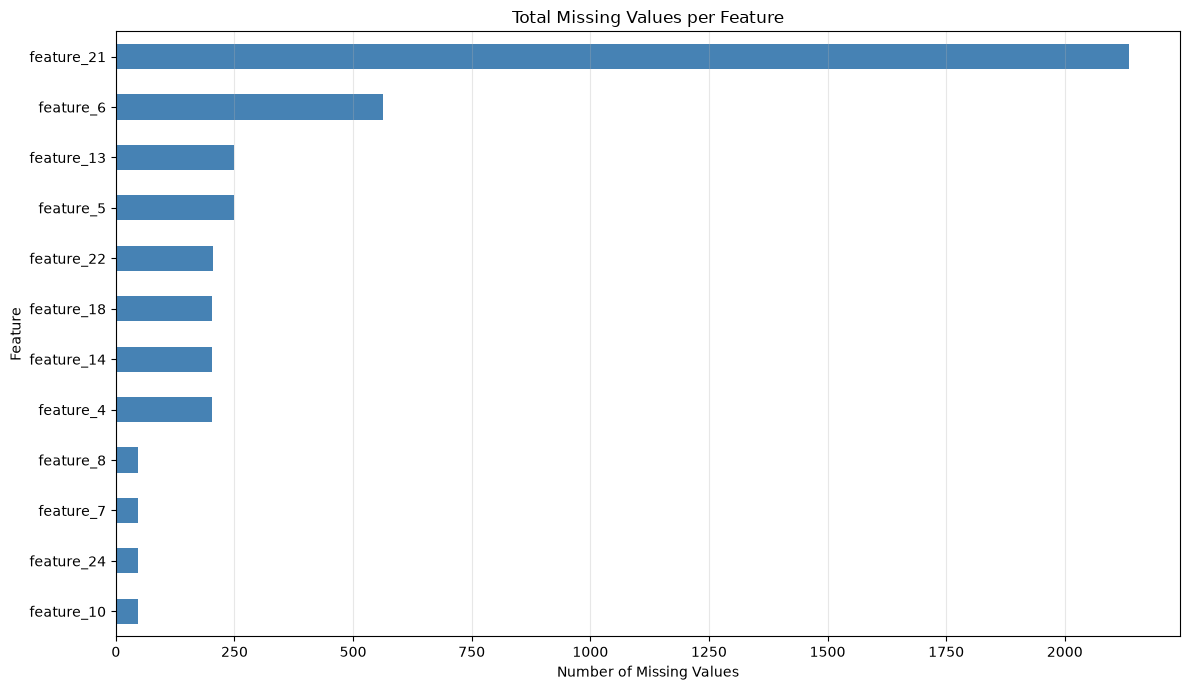

In [7]:

# Total missing values per feature

missing_by_feature = (
    interval_df.groupby("Feature")["Missing Count"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 7))

missing_by_feature.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Total Missing Values per Feature")
plt.xlabel("Number of Missing Values")
plt.ylabel("Feature")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
# Check missing values in both training and testing datasets

train_missing = train_df[feature_cols].isnull().sum()
test_missing = test_df[feature_cols].isnull().sum()

missing_check = pd.DataFrame({
    "Training Missing": train_missing,
    "Testing Missing": test_missing
})

missing_check = missing_check[
    (missing_check["Training Missing"] > 0) |
    (missing_check["Testing Missing"] > 0)
]

display(missing_check)

print("Total training missing values:", train_missing.sum())
print("Total testing missing values:", test_missing.sum())

,Training Missing,Testing Missing
feature_4,202,0
feature_5,249,0
feature_6,563,0
feature_7,47,0
feature_8,47,0
feature_10,47,0
feature_13,249,0
feature_14,202,0
feature_18,202,0
feature_21,2136,0


Total training missing values: 4195
Total testing missing values: 0


In [9]:

# Initialize Median Imputer
imputer = SimpleImputer(strategy="median")

# Create copies of original datasets
train_df_processed = train_df.copy()
test_df_processed = test_df.copy()

# Fit on training data and transform
train_df_processed[feature_cols] = imputer.fit_transform(
    train_df[feature_cols]
)

# Transform testing data using the same imputer
test_df_processed[feature_cols] = imputer.transform(
    test_df[feature_cols]
)

print("Missing value imputation completed successfully!")


Missing value imputation completed successfully!


In [10]:

print("Training missing values after imputation:",
      train_df_processed[feature_cols].isnull().sum().sum())

print("Testing missing values after imputation:",
      test_df_processed[feature_cols].isnull().sum().sum())

print("\nFinal Training Shape:", train_df_processed.shape)
print("Final Testing Shape:", test_df_processed.shape)


Training missing values after imputation: 0
Testing missing values after imputation: 0

Final Training Shape: (132481, 26)
Final Testing Shape: (87841, 26)


In [11]:

# Initialize Standard Scaler
scaler = StandardScaler()

# Create copies of processed datasets
train_df_scaled = train_df_processed.copy()
test_df_scaled = test_df_processed.copy()

# Fit scaler using training data only
train_df_scaled[feature_cols] = scaler.fit_transform(
    train_df_processed[feature_cols]
)

# Apply the same scaler to testing data
test_df_scaled[feature_cols] = scaler.transform(
    test_df_processed[feature_cols]
)

print("Feature scaling completed successfully!")


Feature scaling completed successfully!


In [12]:

print("Scaled Training Shape:", train_df_scaled.shape)
print("Scaled Testing Shape:", test_df_scaled.shape)

print("\nTraining Feature Means:")
print(train_df_scaled[feature_cols].mean().round(4).head())

print("\nTraining Feature Standard Deviations:")
print(train_df_scaled[feature_cols].std().round(4).head())


Scaled Training Shape: (132481, 26)
Scaled Testing Shape: (87841, 26)

Training Feature Means:
feature_0    0.0
feature_1   -0.0
feature_2   -0.0
feature_3    0.0
feature_4    0.0
dtype: float64

Training Feature Standard Deviations:
feature_0    1.0
feature_1    1.0
feature_2    1.0
feature_3    1.0
feature_4    1.0
dtype: float64


In [13]:

# Final preprocessing verification

print("FINAL PREPROCESSING VERIFICATION")
print("=" * 45)

print("Training missing values:",
      train_df_processed[feature_cols].isnull().sum().sum())

print("Testing missing values:",
      test_df_processed[feature_cols].isnull().sum().sum())

print("Training scaled values are finite:",
      np.isfinite(train_df_scaled[feature_cols]).all().all())

print("Testing scaled values are finite:",
      np.isfinite(test_df_scaled[feature_cols]).all().all())

print("Training timestamps sorted:",
      train_df_processed[timestamp_col].is_monotonic_increasing)

print("Testing timestamps sorted:",
      test_df_processed[timestamp_col].is_monotonic_increasing)

print("Test labels aligned:",
      np.array_equal(
          test_df_processed[timestamp_col].to_numpy(),
          test_label_df[timestamp_col].to_numpy()
      ))

print("\nPreprocessing completed successfully!")


FINAL PREPROCESSING VERIFICATION
Training missing values: 0
Testing missing values: 0
Training scaled values are finite: True
Testing scaled values are finite: True
Training timestamps sorted: True
Testing timestamps sorted: True
Test labels aligned: True

Preprocessing completed successfully!


In [14]:

# Save processed datasets

from pathlib import Path

# Locate processed folder
possible_dirs = [
    Path("data/processed"),
    Path("../data/processed")
]

PROCESSED_DIR = next(
    (p for p in possible_dirs if p.exists()),
    possible_dirs[0]
)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save imputed datasets
train_df_processed.to_csv(
    PROCESSED_DIR / "train_imputed.csv",
    index=False
)

test_df_processed.to_csv(
    PROCESSED_DIR / "test_imputed.csv",
    index=False
)

# Save scaled datasets
train_df_scaled.to_csv(
    PROCESSED_DIR / "train_scaled.csv",
    index=False
)

test_df_scaled.to_csv(
    PROCESSED_DIR / "test_scaled.csv",
    index=False
)

# Save test labels
test_label_df.to_csv(
    PROCESSED_DIR / "test_labels.csv",
    index=False
)

print("All processed datasets saved successfully!")

print("\nSaved files:")
for file in sorted(PROCESSED_DIR.glob("*.csv")):
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")


All processed datasets saved successfully!

Saved files:
test_imputed.csv - 41612.63 KB
test_labels.csv - 1029.41 KB
test_scaled.csv - 43163.33 KB
train_imputed.csv - 62346.18 KB
train_scaled.csv - 64851.11 KB
